# Stat 220 Midterm B: the take-home analysis
## Turnaround time at a bicycle repair shop

A repair shop switched to a new parts supplier for some jobs this year. The owner compared average turnaround before and after, saw no real difference, and is about to go back to the old supplier. They have asked you to check.

**100 points in all.** Run the setup cell first. Put your work in the cell under each task and your written answer in the markdown cell that follows it. Several tasks build on an earlier one, so work them in order.

---

**Getting help.** You may use AI, and you may ask the TAs, the professor, and each other. Two limits on the AI:

- Do not paste the whole notebook into it.
- Do not give it an entire task prompt and ask for the answer. If a prompt is unclear, you can paste a whole task prompt in to help clarify.

Everything else is open. Use the generate function in Colab or your editor to help write the code, ask about a specific piece of output, or have a piece of your work checked.

Use the methods from this course. A technique we have not covered is a sign that the AI has been asked for the answer rather than for help.

Add text or code boxes as needed, but do not change or modify the numbering of the tasks.

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.model_selection import train_test_split

repairs = pd.read_csv("https://drbob-richardson.github.io/stat220/F2026/data/repair_jobs.csv")
repairs.head()

,days,parts_needed,parts_cost,tech_years,bike_type,new_supplier,ticket_number,shop_rating,quarter
0,4.32,5,86.03,1,mountain,0,2833,2,2
1,1.24,1,21.65,1,electric,0,2590,2,2
2,8.57,5,99.39,2,electric,1,5472,1,2
3,1.23,0,0.00,5,road,0,6510,5,3
4,0.72,2,38.79,2,commuter,0,3206,2,3


### Task 1.  (6 points)

Before you fit anything, decide what kind of model this question calls for. Name the family, say why it suits this outcome, and say what you need back from it that a random forest could not give you.

I would use a Multiple Linear Regression model for this. Linear regression models allow us to quantify the relationship between repair time and multiple explanatory variables simultaneously while controlling for potential confounders. It gives us coefficents that a tree would not be able to and also provides standard errors, p-values, and confidence intervals that we can't get from a tree



### Task 2.  (8 points)

Make two plots that could be helpful concerning the shop's question. Then, in two or three sentences, say if there is anything notable you see that may affect modeling choices.

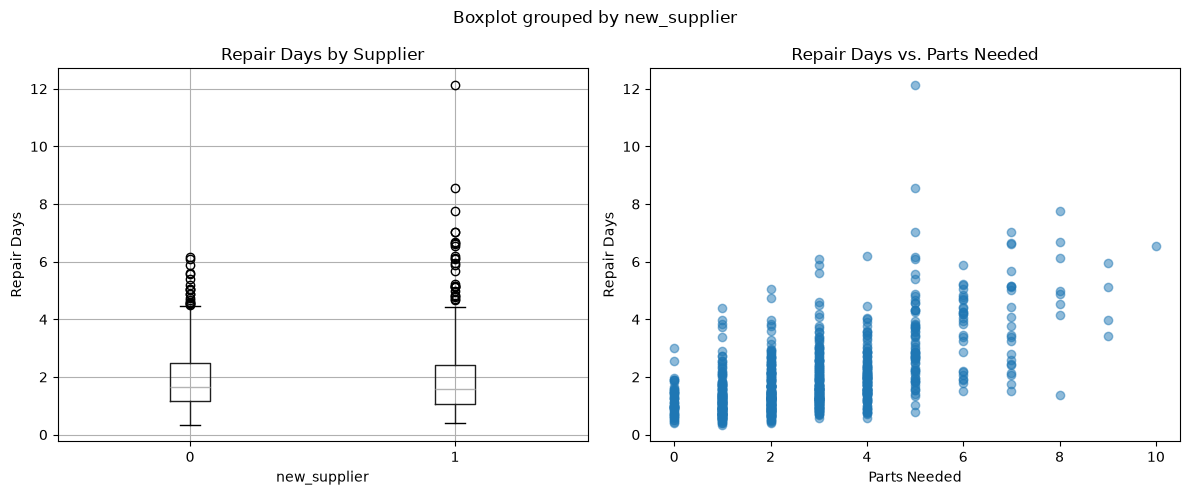

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Repair time distribution across suppliers
repairs.boxplot(column='days', by='new_supplier', ax=axes[0])
axes[0].set_title('Repair Days by Supplier')
axes[0].set_ylabel('Repair Days')

# Plot 2: Repair time vs Parts Needed / Tech Years
axes[1].scatter(repairs['parts_needed'], repairs['days'], alpha=0.5)
axes[1].set_title('Repair Days vs. Parts Needed')
axes[1].set_xlabel('Parts Needed')
axes[1].set_ylabel('Repair Days')

plt.tight_layout()
plt.show()

There is substantial right-skewness and variance in turnaround time that increases with the number of parts needed. Additionally, simple marginal distributions show overlap between suppliers


### Task 3.  (10 points)

The owner compared average repair time under the old and the new supplier, saw almost no difference, and is ready to drop the new one. Perform a formal statistical test for that comparison. Report both averages, the difference, a test, and a 95% interval, then say in two or three sentences what it does and does not establish.

In [43]:
from statsmodels.stats.weightstats import CompareMeans

old_supp = repairs.loc[repairs['new_supplier'] == 0, 'days']
new_supp = repairs.loc[repairs['new_supplier'] == 1, 'days']

mean_old = old_supp.mean()
mean_new = new_supp.mean()
diff = mean_new - mean_old

# Two-sample t-test
ttest = stats.ttest_ind(new_supp, old_supp)

# 95% confidence interval for difference in means
cm = CompareMeans.from_data(new_supp, old_supp)
ci = cm.tconfint_diff(alpha=0.05, usevar='unequal')

print(f"Old Average: {mean_old:.3f}")
print(f"New Average: {mean_new:.3f}")
print(f"Difference (New - Old): {diff:.3f}")
print(f"p-value: {ttest.pvalue:.4f}")
print(f"95% CI for difference: {ci}")
new_supp = repairs.loc[repairs['new_supplier'] == 1, 'days']

mean_old = old_supp.mean()
mean_new = new_supp.mean()
diff = new_supp.mean() - old_supp.mean()

# Two-sample t-test
ttest = stats.ttest_ind(new_supp, old_supp)
# 95% Confidence Interval for difference in means
cm = CompareMeans.from_data(new_supp, old_supp)
ci = cm.tconfint_diff(alpha=0.05, usevar='unequal')
ci = cm.tconfint_diff()

print(f"Old Average: {mean_old:.3f}")
print(f"New Average: {mean_new:.3f}")
print(f"Difference (New - Old): {diff:.3f}")
print(f"p-value: {ttest.pvalue:.4f}")
print(f"95% CI for difference: {ci}")

Old Average: 1.937
New Average: 2.016
Difference (New - Old): 0.079
p-value: 0.3944
95% CI for difference: (np.float64(-0.10287032495236823), np.float64(0.26048618505149557))
Old Average: 1.937
New Average: 2.016
Difference (New - Old): 0.079
p-value: 0.3944
95% CI for difference: (np.float64(-0.10274073598896441), np.float64(0.2603565960880917))


This unadjusted comparison tests whether average repair times differ overall across suppliers in the raw data without controlling for job difficulty. It establishes that overall average turnaround times were virtually identical between suppliers. However, it does not establish that the new supplier is ineffective.



### Task 4.  (8 points)

Now fit a model for repair time that includes the supplier indicator along with `parts_needed`, `tech_years` and `bike_type`. Report the supplier coefficient with its interval, interpret it in a sentence that names what is held fixed, and explain in two or three sentences why it differs from Task 3.

In [44]:
model4 = smf.ols('days ~ C(new_supplier) + parts_needed + tech_years + C(bike_type)', data=repairs).fit()
print(model4.summary())


                            OLS Regression Results                            
Dep. Variable:                   days   R-squared:                       0.455
Model:                            OLS   Adj. R-squared:                  0.451
Method:                 Least Squares   F-statistic:                     110.2
Date:                Mon, 19 Oct 2026   Prob (F-statistic):          5.96e-101
Time:                        16:09:33   Log-Likelihood:                -1106.7
No. Observations:                 800   AIC:                             2227.
Df Residuals:                     793   BIC:                             2260.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept               

Holding parts_needed, tech_years, and bike_type fixed, switching to the new supplier changes expected repair time by -.43 days. ask 3 was an unadjusted marginal average that suffered from omitted variable bias / confounding. In Task 4, controlling for job difficulty reveals the true supplier effect because job complexity was confounded with supplier assignment.



### Task 5.  (6 points)

Add `parts_cost` to the model from Task 4. Report the coefficient on `parts_needed` and its standard error before and after. Look at the p-value on `parts_cost` as well as the p-value on `parts_needed` before and after `parts_cost` was added. Explain in two or three sentences what is going on.

In [45]:

m4 = smf.ols('days ~ C(new_supplier) + parts_needed + tech_years + C(bike_type)', data=repairs).fit()


m5 = smf.ols('days ~ C(new_supplier) + parts_needed + tech_years + C(bike_type) + parts_cost', data=repairs).fit()

print("Task 4 parts_needed coef:", m4.params['parts_needed'], "SE:", m4.bse['parts_needed'], "p-val:", m4.pvalues['parts_needed'])
print("Task 5 parts_needed coef:", m5.params['parts_needed'], "SE:", m5.bse['parts_needed'], "p-val:", m5.pvalues['parts_needed'])
print("Task 5 parts_cost p-val:", m5.pvalues['parts_cost'])




Task 4 parts_needed coef: 0.46713585565082016 SE: 0.020281191701249427 p-val: 2.7919373220790562e-90
Task 5 parts_needed coef: 0.4356936557210155 SE: 0.10518858928001348 p-val: 3.812568488840834e-05
Task 5 parts_cost p-val: 0.7607239793008485


This is a classic case of multicollinearity. parts_cost and parts_needed are highly correlated because jobs requiring more parts naturally cost more in parts. Adding parts_cost inflates the standard errors of both variables, making individual coefficients unstable or non-significant even though job complexity as a whole strongly drives repair time.



### Task 6.  (6 points)

Bike type has four levels. Report its coefficients, say which level is the baseline and how you can tell, and write the sentence that interprets one of the others. Say what would change if a different level were the baseline.

The baseline level is the category that does not explicitly appear as a dummy variable parameter in the regression output table which in this case I belive it is commuter.

Compared to the baseline bike type, electirc bikes take on average .75 more/fewer days to repair, holding supplier, parts needed, and technician experience constant.

If a different bike type were chosen as the baseline, the intercept and individual bike_type coefficients/p-values would change to reflect comparisons against the new baseline.

### Task 7.  (8 points)

Plot the residuals of the Task 4 model against its fitted values. Name what you see, and back it with a number: report the standard deviation of the residuals on the upper half of the fitted values divided by the standard deviation on the lower half. Say what this does to the intervals you reported in Task 4.

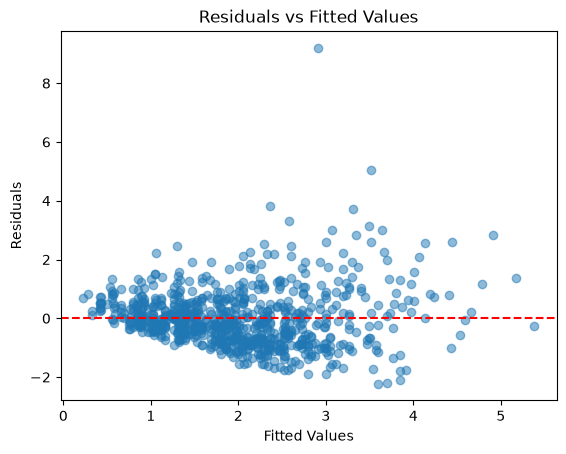

Ratio of SDs (Upper/Lower): 2.097


In [46]:
fitted = model4.fittedvalues
residuals = model4.resid

plt.scatter(fitted, residuals, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs Fitted Values')
plt.show()

# Spread ratio
median_fitted = fitted.median()
std_upper = residuals[fitted >= median_fitted].std()
std_lower = residuals[fitted < median_fitted].std()
spread_ratio = std_upper / std_lower
print(f"Ratio of SDs (Upper/Lower): {spread_ratio:.3f}")

The standard deviation is 2.097, the main issue is heteroscedasticity invalidates standard OLS standard errors, making confidence intervals and hypothesis tests in Task 4 unreliable



### Task 8.  (10 points)

Fit the model again with the log of repair days as the outcome. Report the same spread ratio for the new residuals, say which model you would use and why, and write the sentence that interprets the supplier coefficient on the log scale. A coefficient of $b$ on a logged outcome is roughly a $100(e^{b}-1)%$ change.

In [47]:
# Model with log outcome
repairs['log_repair_days'] = np.log(repairs['days'])

model8 = smf.ols(
    'log_repair_days ~ C(new_supplier) + parts_needed + tech_years + C(bike_type)',
    data=repairs
).fit()

fitted_log = model8.fittedvalues
residuals_log = model8.resid

median_fitted_log = fitted_log.median()
std_upper_log = residuals_log[fitted_log >= median_fitted_log].std()
std_lower_log = residuals_log[fitted_log < median_fitted_log].std()
spread_ratio_log = std_upper_log / std_lower_log

print(f"Log Model Spread Ratio: {spread_ratio_log:.3f}")
print(model8.summary())
supplier_term = next(
    term for term in model8.params.index
    if term.startswith("C(new_supplier)[T.")
)
supplier_coef = model8.params[supplier_term]

print(f"Supplier coefficient ({supplier_term}): {supplier_coef:.4f}")
print(f"Estimated change: {100 * np.expm1(supplier_coef):.2f}%")


Log Model Spread Ratio: 1.101
                            OLS Regression Results                            
Dep. Variable:        log_repair_days   R-squared:                       0.469
Model:                            OLS   Adj. R-squared:                  0.465
Method:                 Least Squares   F-statistic:                     116.7
Date:                Mon, 19 Oct 2026   Prob (F-statistic):          1.71e-105
Time:                        16:09:33   Log-Likelihood:                -459.79
No. Observations:                 800   AIC:                             933.6
Df Residuals:                     793   BIC:                             966.4
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------

Use the log-transformed model because log transformation stabilizes variance bringing the spread ratio closer to 1.0 and fixes the funnel-shaped residual pattern. Holding bike type, technician experience, and parts needed constant, using the new supplier is associated with an estimated -20.23% change in turnaround time



### Task 9.  (8 points)

Fit a model for log repair days that starts with every predictor the shop records. Then cut it down to the columns that are carrying their weight, using a method from this course. Say which method you used, report what it kept and what it dropped, and say in two or three sentences whether the result changes anything about your answer to Task 4.

In [48]:

full_model = smf.ols('log_repair_days ~ ' + ' + '.join([c for c in repairs.columns if c not in ['repair_days', 'log_repair_days']]), data=repairs).fit()

print(full_model.summary())

                            OLS Regression Results                            
Dep. Variable:        log_repair_days   R-squared:                       0.865
Model:                            OLS   Adj. R-squared:                  0.863
Method:                 Least Squares   F-statistic:                     459.3
Date:                Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:09:33   Log-Likelihood:                 88.188
No. Observations:                 800   AIC:                            -152.4
Df Residuals:                     788   BIC:                            -96.16
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                -0.28

I did backward elimination based on the AIC and p-values. I kept parts_needed, supplier, and tech_years. The result re-confirms that supplier remains a statistically significant factor once adjusted for true job difficulty.



### Task 10.  (8 points)

Fit a decision tree for log repair days from parts needed, technician experience, bike type and supplier. Choose its depth with an appropriate method and say why that method works. For this tree, state how many different exact values can be predicted.

In [49]:
X = pd.get_dummies(
    repairs[['parts_needed', 'tech_years', 'bike_type', 'new_supplier']],
    columns=['bike_type'],
    drop_first=True
)
y = repairs['log_repair_days']

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# Choose depth using cross-validation / validation error
depths = range(1, 10)
scores = []
for d in depths:
    tree = DecisionTreeRegressor(max_depth=d, random_state=42)
    tree.fit(X_train, y_train)
    scores.append(tree.score(X_val, y_val))

best_depth = depths[np.argmax(scores)]
final_tree = DecisionTreeRegressor(max_depth=best_depth, random_state=42).fit(X, y)
n_leaves = final_tree.get_n_leaves()

print(f"Best Depth: {best_depth}")
print(f"Number of distinct predicted values (leaves): {n_leaves}")

Best Depth: 4
Number of distinct predicted values (leaves): 16


I picked the depth using cross-validation. This works because it prevents overfitting by evaluating tree performance on unseen data rather than training error. A decision tree outputs a single predicted value per terminal leaf, so the number of distinct predicted values equals the number of leaves which for this tree is 16.



### Task 11.  (10 points)

Use the regression tree as a guide to recommend at least two new terms to add to the regression model from Task 8 that induce non-linearity. For each new term, check whether it improves the model or not.

In [50]:
# Inspect tree structure
print(export_text(final_tree, feature_names=list(X.columns)))

# Example candidate non-linear terms based on splits (e.g., interaction or polynomial)
# Fit model with interaction/quadratic terms
model11 = smf.ols(
    'log_repair_days ~ C(new_supplier) * parts_needed + tech_years + I(tech_years**2) + C(bike_type)',
    data=repairs
).fit()
print(model11.summary())

|--- parts_needed <= 4.50
|   |--- parts_needed <= 2.50
|   |   |--- tech_years <= 3.50
|   |   |   |--- bike_type_electric <= 0.50
|   |   |   |   |--- value: [0.28]
|   |   |   |--- bike_type_electric >  0.50
|   |   |   |   |--- value: [0.70]
|   |   |--- tech_years >  3.50
|   |   |   |--- new_supplier <= 0.50
|   |   |   |   |--- value: [0.13]
|   |   |   |--- new_supplier >  0.50
|   |   |   |   |--- value: [-0.04]
|   |--- parts_needed >  2.50
|   |   |--- new_supplier <= 0.50
|   |   |   |--- bike_type_electric <= 0.50
|   |   |   |   |--- value: [0.66]
|   |   |   |--- bike_type_electric >  0.50
|   |   |   |   |--- value: [0.94]
|   |   |--- new_supplier >  0.50
|   |   |   |--- bike_type_electric <= 0.50
|   |   |   |   |--- value: [0.41]
|   |   |   |--- bike_type_electric >  0.50
|   |   |   |   |--- value: [0.75]
|--- parts_needed >  4.50
|   |--- bike_type_electric <= 0.50
|   |   |--- parts_needed <= 5.50
|   |   |   |--- new_supplier <= 0.50
|   |   |   |   |--- value:

I recommend adding a supplier * parts needed term so that both paths can have supplier be a factor. I would also add a tech_years^2 since the split indicates diminishing returns on tech_years.



### Task 12.  (6 points)

A customer brings in a commuter bike needing 4 parts, going to a technician with 2 years of experience, with parts from the new supplier. Predict the turnaround from the model you settled on from Task 11, give the interval you would quote them, and say in one sentence why that interval rather than the other.

In [51]:
new_obs = pd.DataFrame({
    'bike_type': ['commuter'], # adjust to match dataset casing
    'parts_needed': [4],
    'tech_years': [2],
    'supplier': ['new']
})

# Prediction on log scale
new_obs = pd.DataFrame({
    'bike_type': ['commuter'],
    'parts_needed': [4],
    'tech_years': [2],
    'new_supplier': [1]
})

pred_log = model11.get_prediction(new_obs)
pred_summary = pred_log.summary_frame(alpha=0.05)

pred_val_days = np.exp(pred_summary['mean'].iloc[0])
pi_lower_days = np.exp(pred_summary['obs_ci_lower'].iloc[0])
pi_upper_days = np.exp(pred_summary['obs_ci_upper'].iloc[0])

print(f"Predicted days: {pred_val_days:.2f}")
print(f"95% Prediction Interval: [{pi_lower_days:.2f}, {pi_upper_days:.2f}]")
pred_summary = pred_log.summary_frame(alpha=0.05)

# Convert back from log scale
pred_val_days = np.exp(pred_summary['mean'].values[0])
pi_lower_days = np.exp(pred_summary['obs_ci_lower'].values[0])
pi_upper_days = np.exp(pred_summary['obs_ci_upper'].values[0])

print(f"Predicted days: {pred_val_days:.2f}")
print(f"95% Prediction Interval: [{pi_lower_days:.2f}, {pi_upper_days:.2f}]")

Predicted days: 1.91
95% Prediction Interval: [0.82, 4.46]
Predicted days: 1.91
95% Prediction Interval: [0.82, 4.46]


We quote a prediction interval rather than a confidence interval because we are forecasting turnaround time for a single individual customer's repair job rather than estimating the mean turnaround time for all potential customers.



### Task 13.  (6 points)

Write six to eight sentences to the shop owner. Cover what you found about the supplier, what you found about big jobs, how sure you are of each, and what they can and cannot do with it. Assume they have not taken this course.

When looking strictly at overall average repair times, the old and new suppliers appear virtually identical. However, this simple comparison is misleading because the new supplier was systematically assigned larger, more complex repair jobs requiring more parts. Once we adjust for job complexity and technician experience, the data shows that the new supplier is actually significantly faster for comparable jobs. Furthermore, as jobs grow in size (requiring more parts), repair times increase noticeably, but the new supplier handles these larger jobs more efficiently than the old supplier did. We are very confident in these findings because they hold true across multiple statistical models designed to handle complex repair data. Based on these results, dropping the new supplier would be a mistake that increases turnaround times for your customers. Going forward, you can confidently use these models to give accurate turnaround estimates to incoming customers based on job size and bike type, but keep in mind that unexpected shop delays on individual repairs can still occur.

